# Task 1:

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Use a new image from the Lab 8 folder, not the original notebook image.
image = cv2.imread("Butterfly.jpg")

if image is None:
    raise FileNotFoundError("Butterfly.jpg could not be loaded.")

image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
blurred = cv2.GaussianBlur(gray, (5, 5), 0)


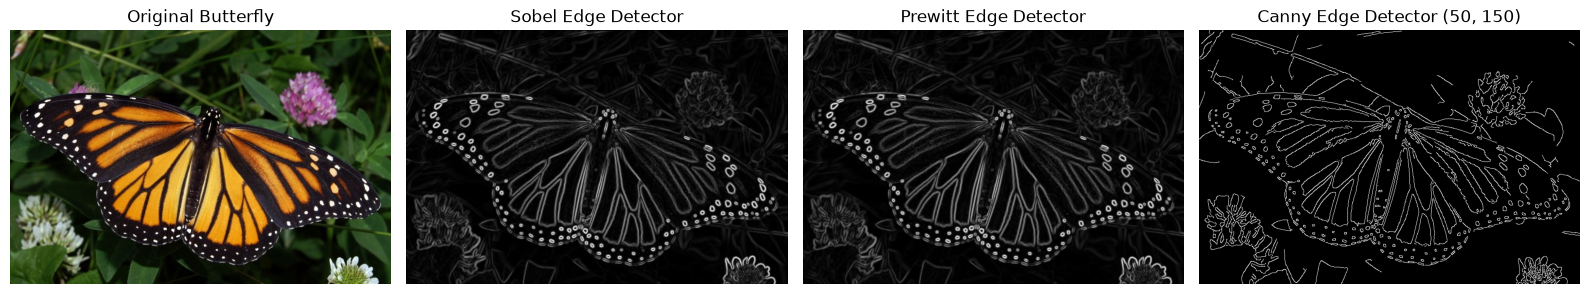

In [2]:
# Sobel Edge Detector
sobel_x = cv2.Sobel(blurred, cv2.CV_32F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(blurred, cv2.CV_32F, 0, 1, ksize=3)
sobel_magnitude = cv2.magnitude(sobel_x, sobel_y)
sobel_edges = cv2.normalize(sobel_magnitude, None, 0, 255,
                            cv2.NORM_MINMAX).astype(np.uint8)

# Prewitt Edge Detector
prewitt_x_kernel = np.array([[-1, 0, 1],
                             [-1, 0, 1],
                             [-1, 0, 1]], dtype=np.float32)
prewitt_y_kernel = np.array([[-1, -1, -1],
                             [ 0,  0,  0],
                             [ 1,  1,  1]], dtype=np.float32)
prewitt_x = cv2.filter2D(blurred, cv2.CV_32F, prewitt_x_kernel)
prewitt_y = cv2.filter2D(blurred, cv2.CV_32F, prewitt_y_kernel)
prewitt_magnitude = cv2.magnitude(prewitt_x, prewitt_y)
prewitt_edges = cv2.normalize(prewitt_magnitude, None, 0, 255,
                              cv2.NORM_MINMAX).astype(np.uint8)

# Canny Edge Detector
canny_edges = cv2.Canny(blurred, 50, 150)

# Display the original image and the three edge maps
images = [image, sobel_edges, prewitt_edges, canny_edges]
titles = ["Original Butterfly", "Sobel Edge Detector",
          "Prewitt Edge Detector", "Canny Edge Detector (50, 150)"]

fig, ax = plt.subplots(1, 4, figsize=(16, 5))
for axis, result, title in zip(ax, images, titles):
    if result.ndim == 2:
        axis.imshow(result, cmap="gray", vmin=0, vmax=255)
    else:
        axis.imshow(result)
    axis.set_title(title)
    axis.axis("off")

plt.tight_layout()
plt.show()

# Task 2:

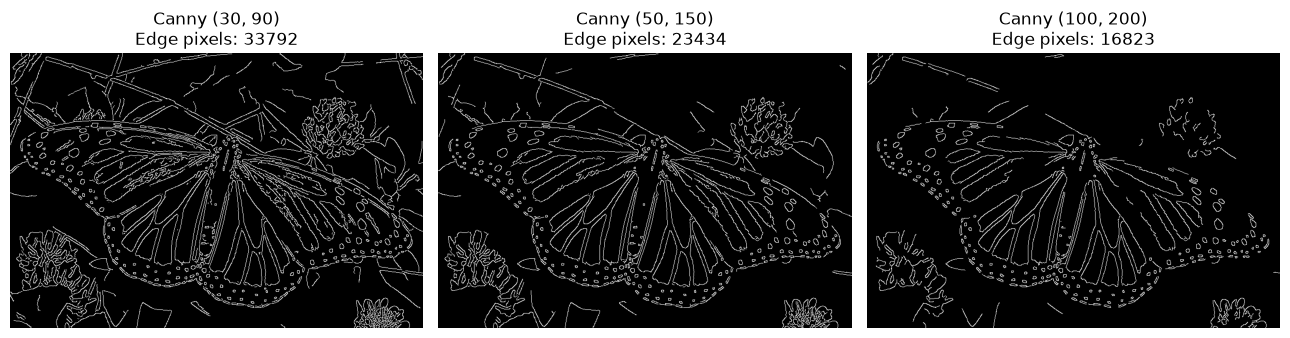

Thresholds (30, 90): 33792 edge pixels
Thresholds (50, 150): 23434 edge pixels
Thresholds (100, 200): 16823 edge pixels


In [3]:
threshold_pairs = [(30, 90), (50, 150), (100, 200)]
canny_results = []

for low_threshold, high_threshold in threshold_pairs:
    edges = cv2.Canny(blurred, low_threshold, high_threshold)
    canny_results.append(edges)

fig, ax = plt.subplots(1, 3, figsize=(13, 4))

for axis, edges, (low_threshold, high_threshold) in zip(
        ax, canny_results, threshold_pairs):
    edge_count = np.count_nonzero(edges)
    axis.imshow(edges, cmap="gray", vmin=0, vmax=255)
    axis.set_title(f"Canny ({low_threshold}, {high_threshold})\n"
                   f"Edge pixels: {edge_count}")
    axis.axis("off")

plt.tight_layout()
plt.show()

for (low_threshold, high_threshold), edges in zip(threshold_pairs, canny_results):
    print(f"Thresholds ({low_threshold}, {high_threshold}): "
          f"{np.count_nonzero(edges)} edge pixels")

**Effect of the thresholds:** Lower thresholds retain weaker edge responses, so more boundaries and fine details appear, along with more noise. Higher thresholds suppress weak responses and usually leave fewer, stronger edges. Canny's hysteresis step keeps weak edges when they connect to strong ones, so changing either threshold can also affect continuity.